In [1]:
!pip -q install idc-index pydicom SimpleITK ultralytics

In [2]:
import torch
print(torch.__version__)
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0))

2.14.1+cu130
True
Tesla T4


In [3]:
!wget -q -O ann.zip "https://www.cancerimagingarchive.net/wp-content/uploads/Lung-PET-CT-Dx-Annotations-XML-Files-rev12222020.zip"
!unzip -q ann.zip -d ann
!ls ann

Annotation


In [4]:
!ls ann/Annotation | head

A0001
A0002
A0003
A0004
A0005
A0006
A0007
A0008
A0009
A0010


In [5]:
!ls ann/Annotation/A0001 | head

1.3.6.1.4.1.14519.5.2.1.6655.2359.102500633407588554681658808214.xml
1.3.6.1.4.1.14519.5.2.1.6655.2359.103293611003651848123608366756.xml
1.3.6.1.4.1.14519.5.2.1.6655.2359.136943255924913899762603730997.xml
1.3.6.1.4.1.14519.5.2.1.6655.2359.155870813347987660555133803380.xml
1.3.6.1.4.1.14519.5.2.1.6655.2359.184131899543495374569818432657.xml
1.3.6.1.4.1.14519.5.2.1.6655.2359.185555685346057091761687385642.xml
1.3.6.1.4.1.14519.5.2.1.6655.2359.187586942311847648079258238193.xml
1.3.6.1.4.1.14519.5.2.1.6655.2359.191468104323452587789797624004.xml
1.3.6.1.4.1.14519.5.2.1.6655.2359.216515627058008697217695696166.xml
1.3.6.1.4.1.14519.5.2.1.6655.2359.217649008723153656849717286154.xml


In [6]:
!cat ann/Annotation/A0001/1.3.6.1.4.1.14519.5.2.1.6655.2359.102500633407588554681658808214.xml

<annotation verified="no">
  <folder>Unknow</folder>
  <filename>Unknow</filename>
  <path>Unknow</path>
  <source>Unknow<database>Unknown</database>
  </source>
  <size>
    <width>512</width>
    <height>512</height>
    <depth>1</depth>
  </size>
  <segmented>0</segmented>
  <object>
    <name>A</name>
    <pose>Unspecified</pose>
    <truncated>0</truncated>
    <Difficult>0</Difficult>
    <bndbox>
      <xmin>286</xmin>
      <ymin>310</ymin>
      <xmax>355</xmax>
      <ymax>402</ymax>
    </bndbox>
  </object>
</annotation>

In [7]:
import xml.etree.ElementTree as ET

root = ET.parse("ann/Annotation/A0001/1.3.6.1.4.1.14519.5.2.1.6655.2359.102500633407588554681658808214.xml").getroot()
for obj in root.findall("object"):
    label = obj.findtext("name")
    box = obj.find("bndbox")
    xmin = int(box.findtext("xmin"))
    ymin = int(box.findtext("ymin"))
    xmax = int(box.findtext("xmax"))
    ymax = int(box.findtext("ymax"))
    print(label, xmin, ymin, xmax, ymax)

A 286 310 355 402


In [8]:
import glob

files = glob.glob("ann/Annotation/*/*.xml")
print(len(files))
print(files[0])

31562
ann/Annotation/A0114/1.3.6.1.4.1.14519.5.2.1.6655.2359.255312737627107463225220427934.xml


In [9]:
import os
import pandas as pd

rows = []
bad = []

for f in files:
    patient = os.path.basename(os.path.dirname(f))
    sop = os.path.basename(f).replace(".xml", "")
    try:
        root = ET.parse(f).getroot()
    except ET.ParseError:
        bad.append(f)
        continue
    for obj in root.findall("object"):
        box = obj.find("bndbox")
        rows.append({
            "patient": patient,
            "sop": sop,
            "label": obj.findtext("name"),
            "xmin": int(box.findtext("xmin")),
            "ymin": int(box.findtext("ymin")),
            "xmax": int(box.findtext("xmax")),
            "ymax": int(box.findtext("ymax")),
        })

ann = pd.DataFrame(rows)
print(len(ann), "boxes")
print(len(bad), "bad files")
print(bad[:5])
ann.head()

31659 boxes
1 bad files
['ann/Annotation/A0024/1.3.6.1.4.1.14519.5.2.1.6655.2359.148117780944430339778694852523.xml']


,patient,sop,label,xmin,ymin,xmax,ymax
0,A0114,1.3.6.1.4.1.14519.5.2.1.6655.2359.255312737627...,A,127,355,205,425
1,A0114,1.3.6.1.4.1.14519.5.2.1.6655.2359.104837557978...,A,112,362,181,428
2,A0114,1.3.6.1.4.1.14519.5.2.1.6655.2359.213972444771...,A,113,342,192,427
3,A0114,1.3.6.1.4.1.14519.5.2.1.6655.2359.962962781944...,A,107,340,192,435
4,A0114,1.3.6.1.4.1.14519.5.2.1.6655.2359.791485868431...,A,116,350,185,421


In [10]:
print(ann["patient"].nunique(), "patients")
print(ann["sop"].nunique(), "slices with tumors")
print(ann["label"].value_counts())

357 patients
31399 slices with tumors
label
A        13065
a         7911
G         5270
B         2244
g         2089
b          860
E          201
Q           10
A0192        9
Name: count, dtype: int64


In [11]:
ann["label"] = ann["patient"].str[0]
print(ann["label"].value_counts())

label
A    20987
G     7355
B     3116
E      201
Name: count, dtype: int64


In [12]:
from idc_index import IDCClient

idc = IDCClient()
idx = idc.index
lung = idx[idx["collection_id"] == "lung_pet_ct_dx"]

print(len(lung), "series")
print(lung["Modality"].value_counts())

2606 series
Modality
CT     1162
SR     1091
SEG     220
PT      133
Name: count, dtype: int64


In [13]:
pet_patients = set(lung[lung["Modality"] == "PT"]["PatientID"])
ct_patients = set(lung[lung["Modality"] == "CT"]["PatientID"])

both = sorted(pet_patients & ct_patients)
print(len(both), "patients have both")
print(both[:10])

133 patients have both
['Lung_Dx-A0164', 'Lung_Dx-A0165', 'Lung_Dx-A0166', 'Lung_Dx-A0167', 'Lung_Dx-A0168', 'Lung_Dx-A0169', 'Lung_Dx-A0170', 'Lung_Dx-A0171', 'Lung_Dx-A0173', 'Lung_Dx-A0174']


In [14]:
pid = "Lung_Dx-A0164"
p = lung[lung["PatientID"] == pid]
p = p[p["Modality"].isin(["CT", "PT"])]

print(p[["Modality", "SeriesDescription", "instanceCount", "series_size_MB"]])

       Modality                         SeriesDescription  instanceCount  \
287953       CT                         Thorax  1.0  B31f            399   
287954       CT                         Thorax  1.0  B70f            399   
287960       CT  Range-CT WB  1.0  B30f-Tra-<ALPHA Range>            175   
287961       CT                          CT WB  3.0  B30f            284   
287962       CT  Range-CT WB  1.0  B30f-Tra-<ALPHA Range>            192   
287963       CT                             <ALPHA Range>             46   
287964       PT                          PET WB Corrected            419   

        series_size_MB  
287953      210.569498  
287954      210.569498  
287960      138.063602  
287961      149.883388  
287962      151.475514  
287963       36.206294  
287964       35.250154  


In [15]:
pet_uid = p[p["Modality"] == "PT"]["SeriesInstanceUID"].iloc[0]

idc.download_from_selection(
    downloadDir="dicom",
    seriesInstanceUID=[pet_uid],
    dirTemplate="%PatientID/%Modality_%SeriesInstanceUID",
)
!ls dicom/Lung_Dx-A0164

PT_1.3.6.1.4.1.14519.5.2.1.6655.2359.788162910000882035217022916485


In [16]:
import shutil, pydicom
want = set(ann[ann["patient"] == "A0164"]["sop"])
print(len(want), "annotated slices for this patient")

best_dir, best_matches = None, 0

for uid in p[p["Modality"] == "CT"]["SeriesInstanceUID"]:
    folder = f"dicom/{pid}/CT_{uid}"
    idc.download_from_selection(
        downloadDir="dicom",
        seriesInstanceUID=[uid],
        dirTemplate="%PatientID/%Modality_%SeriesInstanceUID",
    )
    sops = set()
    for f in glob.glob(f"{folder}/*"):
        sops.add(pydicom.dcmread(f, stop_before_pixels=True).SOPInstanceUID)
    matches = len(sops & want)
    print(len(sops), "slices,", matches, "annotated")
    if matches > best_matches:
        if best_dir:
            shutil.rmtree(best_dir)
        best_dir, best_matches = folder, matches
    else:
        shutil.rmtree(folder)

ct_dir = best_dir
print("Best CT:", ct_dir, "with", best_matches, "annotated slices")

586 annotated slices for this patient


399 slices, 163 annotated


399 slices, 161 annotated


175 slices, 108 annotated


284 slices, 37 annotated


192 slices, 109 annotated


46 slices, 8 annotated
Best CT: dicom/Lung_Dx-A0164/CT_1.3.6.1.4.1.14519.5.2.1.6655.2359.301786164983922333015308052757 with 163 annotated slices


In [17]:
import SimpleITK as sitk
import numpy as np

def load_series(folder):
    reader = sitk.ImageSeriesReader()
    files = reader.GetGDCMSeriesFileNames(folder)
    reader.SetFileNames(files)
    return reader.Execute(), files

pet_dir = glob.glob(f"dicom/{pid}/PT_*")[0]

ct_img, ct_files = load_series(ct_dir)
pet_img, pet_files = load_series(pet_dir)

for name, img in [("CT", ct_img), ("PET", pet_img)]:
    print(name, "size:", img.GetSize(), "spacing (mm):", np.round(img.GetSpacing(), 2))

CT size: (512, 512, 399) spacing (mm): [0.78 0.78 0.7 ]
PET size: (200, 200, 419) spacing (mm): [4.07 4.07 2.03]


In [18]:
ct_ref = pydicom.dcmread(ct_files[0], stop_before_pixels=True).FrameOfReferenceUID
pet_ref = pydicom.dcmread(pet_files[0], stop_before_pixels=True).FrameOfReferenceUID
print("Same coordinate system:", ct_ref == pet_ref)

pet_on_ct = sitk.Resample(pet_img, ct_img, sitk.Transform(), sitk.sitkLinear, 0.0, sitk.sitkFloat32)

ct = sitk.GetArrayFromImage(ct_img).astype(np.float32)
pet = sitk.GetArrayFromImage(pet_on_ct)

print("CT array:", ct.shape, " HU range:", ct.min(), "to", ct.max())
print("PET array:", pet.shape, " value range:", pet.min(), "to", pet.max())

Same coordinate system: False
CT array: (399, 512, 512)  HU range: -1024.0 to 1469.0
PET array: (399, 512, 512)  value range: 0.0 to 71007.79


163 boxes on this CT


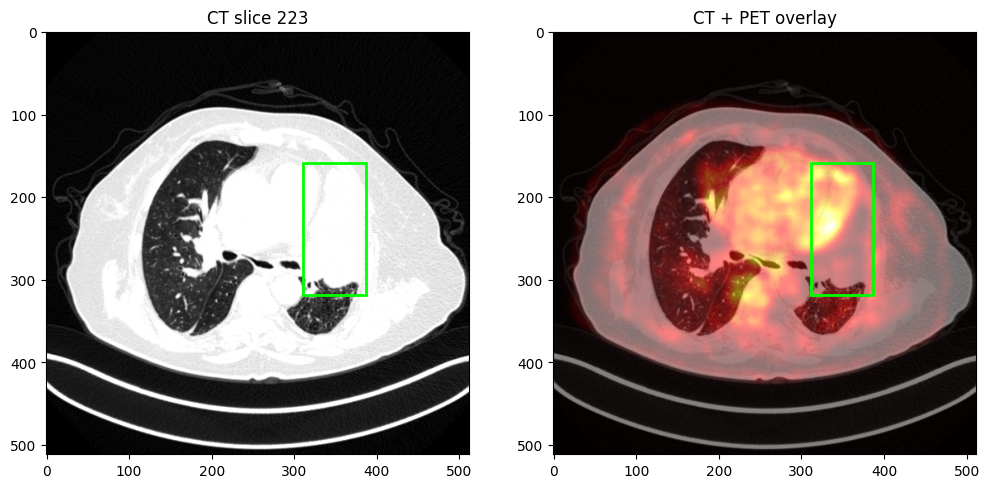

In [19]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

sop_to_z = {}
for i, f in enumerate(ct_files):
    sop_to_z[pydicom.dcmread(f, stop_before_pixels=True).SOPInstanceUID] = i

boxes = ann[(ann["patient"] == "A0164") & (ann["sop"].isin(list(sop_to_z)))]
print(len(boxes), "boxes on this CT")

r = boxes.iloc[len(boxes) // 2]
z = sop_to_z[r["sop"]]

ct_lung = np.clip((ct[z] + 1400) / 1400, 0, 1)
pet_norm = np.clip(pet[z] / np.percentile(pet, 99.5), 0, 1)

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(ct_lung, cmap="gray")
ax[0].set_title(f"CT slice {z}")
ax[1].imshow(ct_lung, cmap="gray")
ax[1].imshow(pet_norm, cmap="hot", alpha=0.5)
ax[1].set_title("CT + PET overlay")
for a in ax:
    a.add_patch(patches.Rectangle((r["xmin"], r["ymin"]), r["xmax"] - r["xmin"], r["ymax"] - r["ymin"],
                                  fill=False, edgecolor="lime", linewidth=2))
plt.show()

Fused shape: (512, 512, 3)


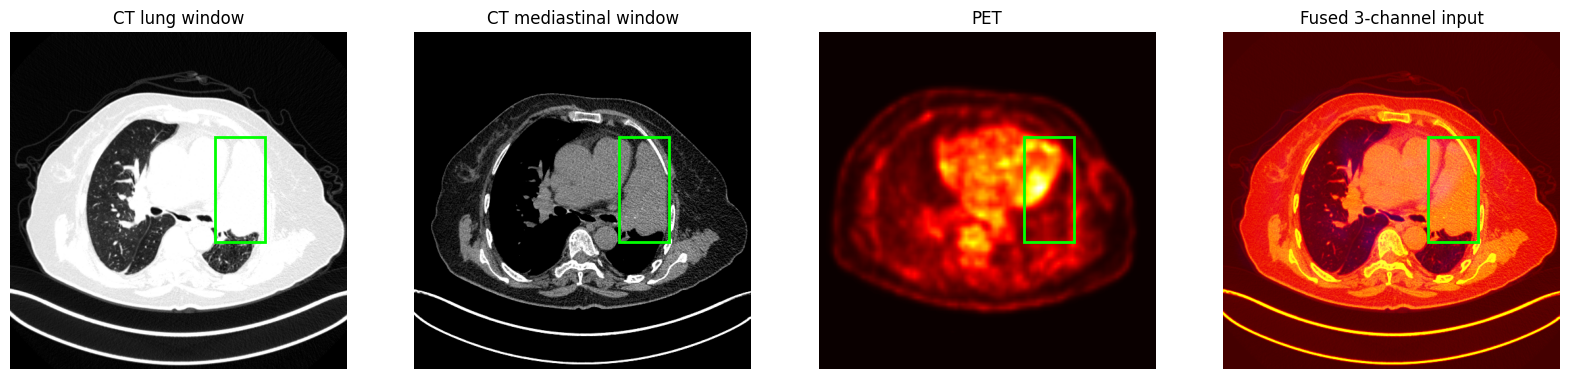

In [20]:
def window(hu, level, width):
    lo = level - width / 2
    hi = level + width / 2
    return np.clip((hu - lo) / (hi - lo), 0, 1)

pet_max = np.percentile(pet, 99.5)

def make_fused(z):
    lung = window(ct[z], -700, 1400)
    medi = window(ct[z], 40, 350)
    pet_ch = np.clip(pet[z] / pet_max, 0, 1)
    return np.stack([lung, medi, pet_ch], axis=-1)

fused = make_fused(z)
print("Fused shape:", fused.shape)

panels = [
    ("CT lung window", window(ct[z], -700, 1400), "gray"),
    ("CT mediastinal window", window(ct[z], 40, 350), "gray"),
    ("PET", np.clip(pet[z] / pet_max, 0, 1), "hot"),
    ("Fused 3-channel input", fused, None),
]

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, (title, img, cmap) in zip(axes, panels):
    ax.imshow(img, cmap=cmap)
    ax.set_title(title)
    ax.axis("off")
    ax.add_patch(patches.Rectangle((r["xmin"], r["ymin"]), r["xmax"] - r["xmin"], r["ymax"] - r["ymin"],
                                   fill=False, edgecolor="lime", linewidth=2))
plt.show()

In [21]:
from PIL import Image
import os

out = "/content/yolo_data"
zs = sorted(boxes["sop"].map(sop_to_z).unique())
cut = int(len(zs) * 0.8)
split_of = {}
for i, zz in enumerate(zs):
    split_of[zz] = "train" if i < cut else "val"

for s in ["train", "val"]:
    os.makedirs(f"{out}/images/{s}", exist_ok=True)
    os.makedirs(f"{out}/labels/{s}", exist_ok=True)

for sop, grp in boxes.groupby("sop"):
    zz = sop_to_z[sop]
    s = split_of[zz]
    name = f"{pid}_{zz:03d}"

    img = (make_fused(zz) * 255).astype(np.uint8)
    Image.fromarray(img).save(f"{out}/images/{s}/{name}.png")

    with open(f"{out}/labels/{s}/{name}.txt", "w") as fh:
        for _, b in grp.iterrows():
            xc = (b["xmin"] + b["xmax"]) / 2 / 512
            yc = (b["ymin"] + b["ymax"]) / 2 / 512
            bw = (b["xmax"] - b["xmin"]) / 512
            bh = (b["ymax"] - b["ymin"]) / 512
            fh.write(f"0 {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}\n")

with open(f"{out}/data.yaml", "w") as fh:
    fh.write(f"path: {out}\ntrain: images/train\nval: images/val\nnames:\n  0: tumor\n")

print("train:", len(os.listdir(f"{out}/images/train")), "val:", len(os.listdir(f"{out}/images/val")))
!cat {out}/labels/train/$(ls {out}/labels/train | head -1)

train: 130 val: 33
0 0.732422 0.479492 0.042969 0.060547


In [22]:
from ultralytics import YOLO

model = YOLO("yolo11n.pt")
results = model.train(
    data="/content/yolo_data/data.yaml",
    epochs=50,
    imgsz=512,
    batch=16,
    project="/content/runs",
    name="fused",
    exist_ok=True,
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_data/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, fre

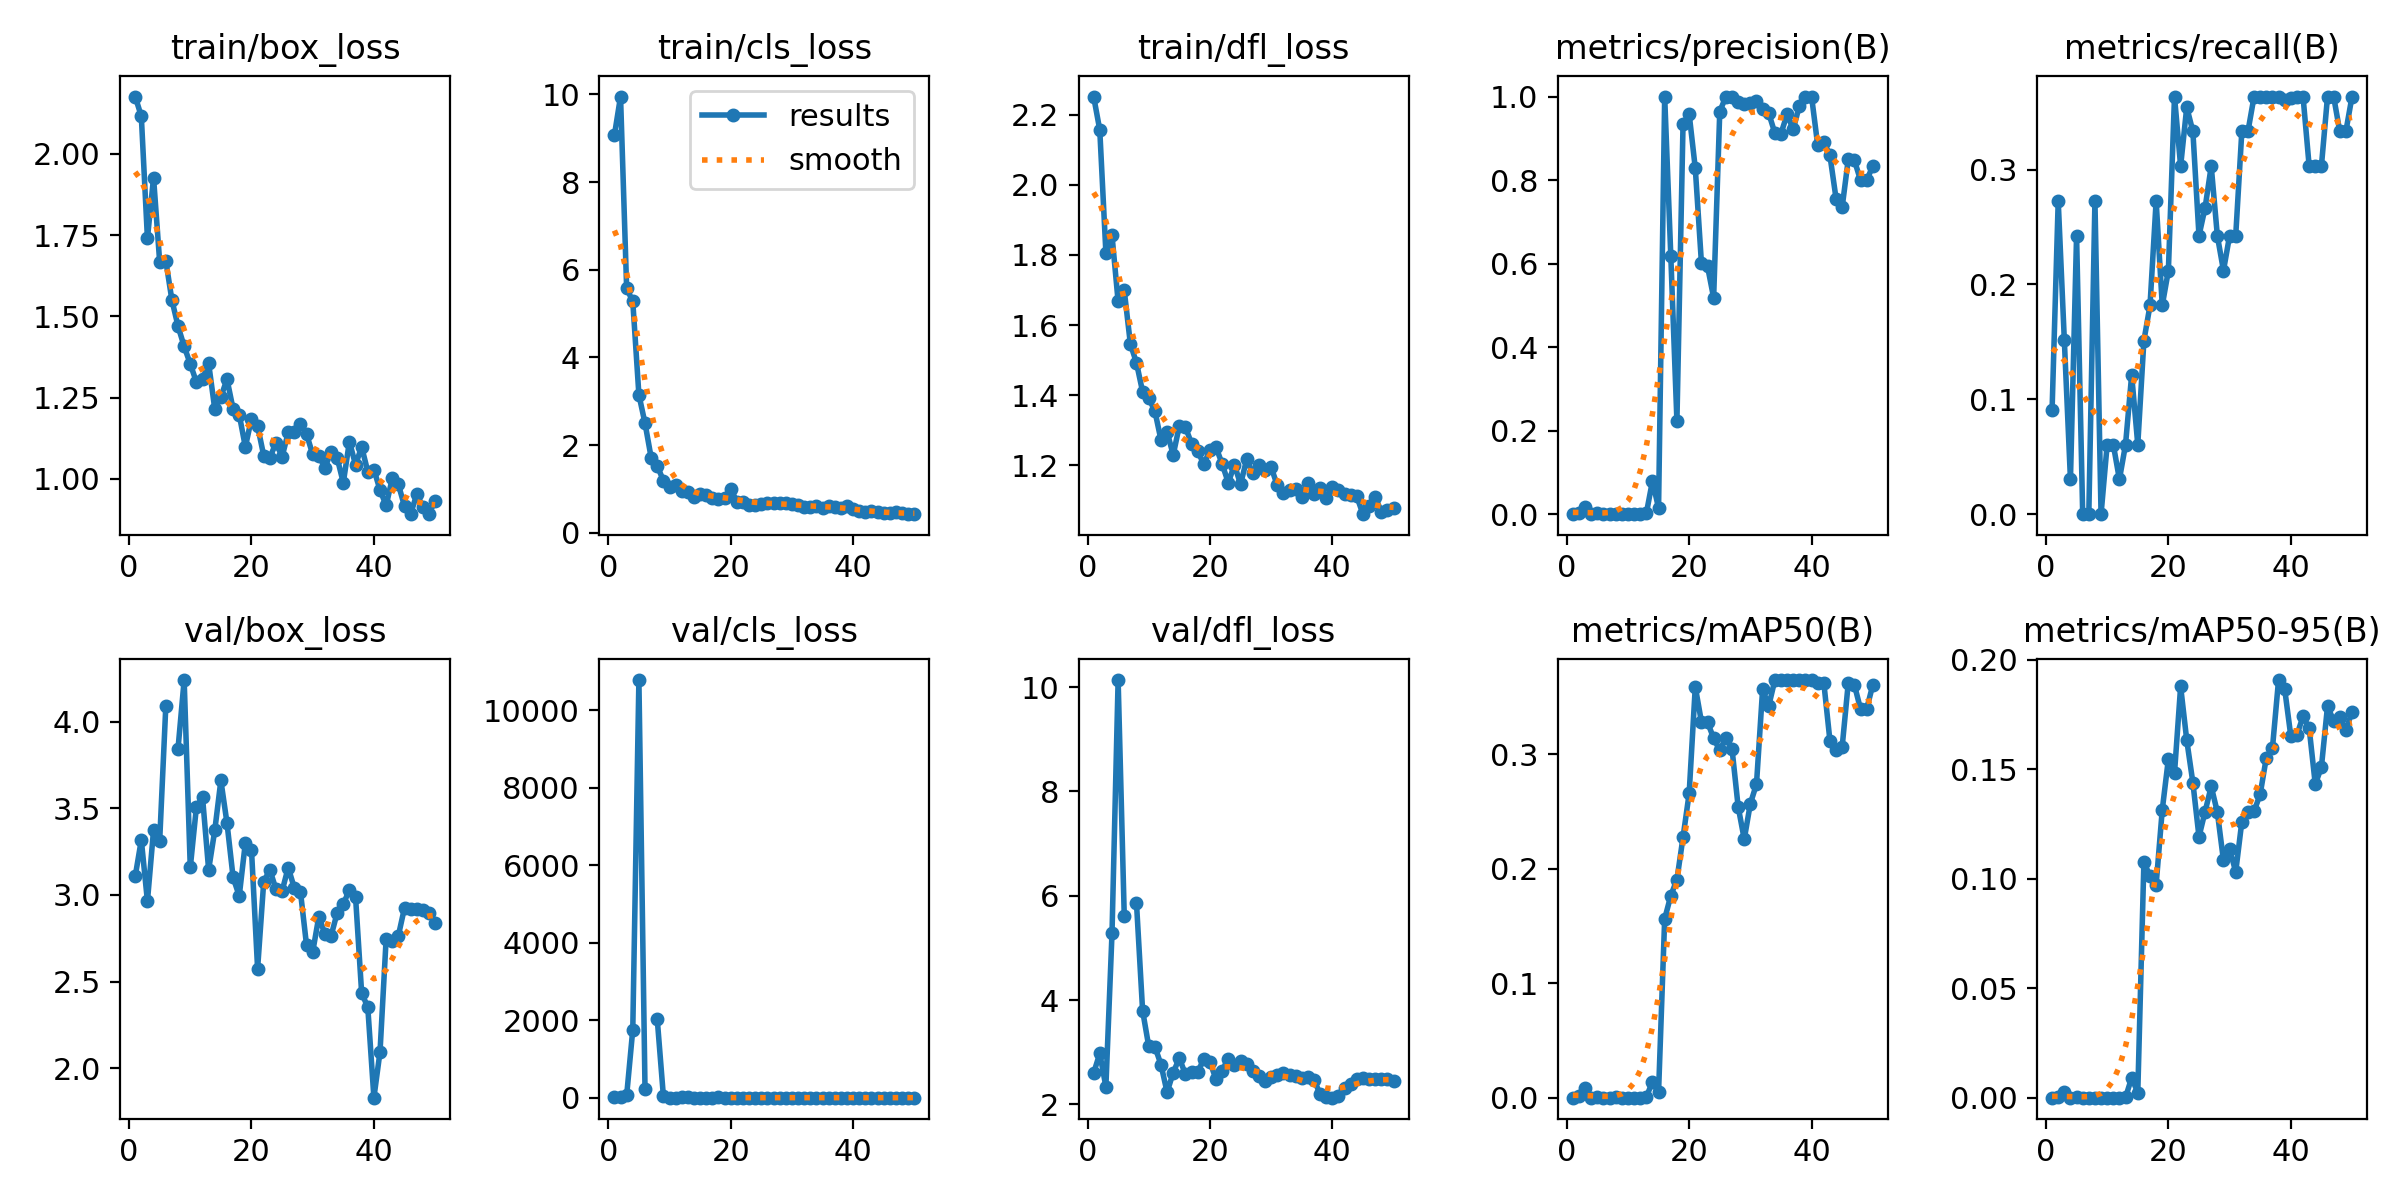

In [23]:
from IPython.display import Image as Show, display
display(Show("/content/runs/fused/results.png", width=1000))

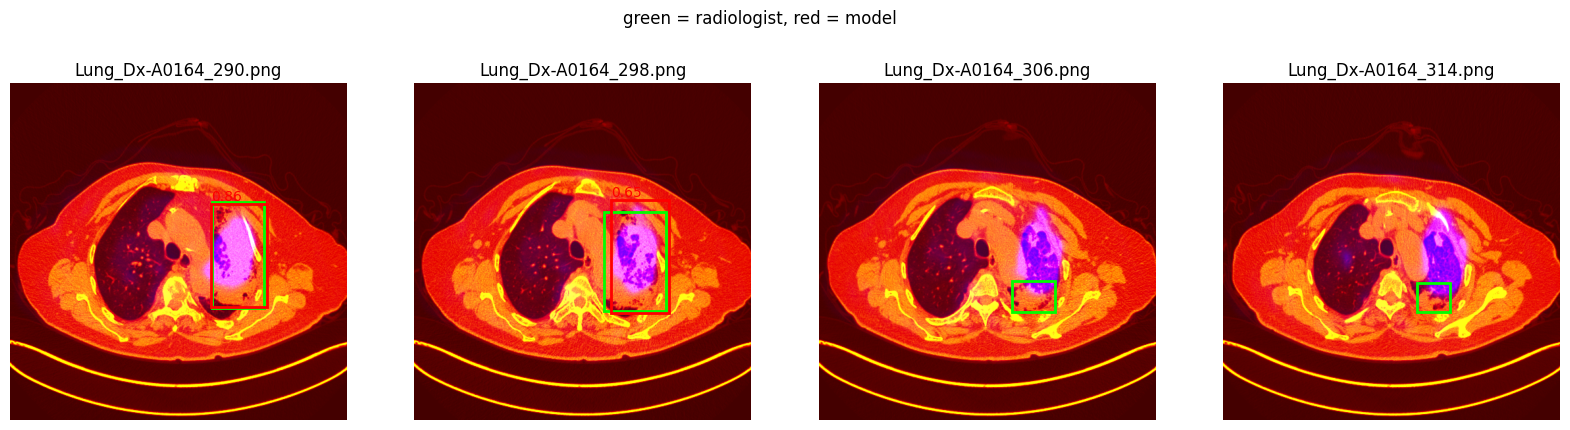

In [24]:
best = YOLO("/content/runs/fused/weights/best.pt")
val_imgs = sorted(glob.glob("/content/yolo_data/images/val/*.png"))
picks = val_imgs[::8][:4]

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, path in zip(axes, picks):
    img = np.array(Image.open(path))
    ax.imshow(img)
    ax.axis("off")
    ax.set_title(os.path.basename(path))

    for line in open(path.replace("images", "labels").replace(".png", ".txt")):
        _, xc, yc, bw, bh = map(float, line.split())
        ax.add_patch(patches.Rectangle(((xc - bw/2) * 512, (yc - bh/2) * 512), bw * 512, bh * 512,
                                       fill=False, edgecolor="lime", linewidth=2))

    pred = best.predict(path, conf=0.25, verbose=False)[0]
    for (x1, y1, x2, y2), s in zip(pred.boxes.xyxy.cpu().numpy(), pred.boxes.conf.cpu().numpy()):
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="red", linewidth=2))
        ax.text(x1, y1 - 5, f"{s:.2f}", color="red", fontsize=10)

plt.suptitle("green = radiologist, red = model")
plt.show()